# E3: LSTM, GRU trên chuỗi ảnh Fashion-MNIST

Notebook này chạy toàn bộ pipeline của bài E3 trên Colab. Cần bật GPU bằng cách vào Runtime, chọn Change runtime type, rồi chọn GPU.

E3 dùng lại đúng dataset, split và checkpoint MLP, CNN đã có từ E1, nên nhánh được clone phải đã chứa cả thư mục E1 với kết quả đã train, không chỉ thư mục E3. Nếu đang làm việc trên một nhánh khác main thì sửa biến BRANCH ở cell bên dưới cho đúng tên nhánh đó.

In [1]:
!nvidia-smi

Mon Nov  9 06:57:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   56C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 1. Clone repo và chuyển vào thư mục E3

In [2]:
import os

REPO_URL = "https://github.com/truong1501/SDH_HK261_CO5085.git"
REPO_DIR = "/content/SDH_HK261_CO5085"
BRANCH = "main"  # doi lai dung nhanh dang chua thu muc E3/

if not os.path.exists(REPO_DIR):
    !git clone --branch {BRANCH} {REPO_URL} {REPO_DIR}
else:
    !cd {REPO_DIR} && git checkout {BRANCH} && git pull

%cd {REPO_DIR}/E3

Cloning into '/content/SDH_HK261_CO5085'...
remote: Enumerating objects: 545, done.
remote: Counting objects: 100% (41/41), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 545 (delta 13), reused 25 (delta 12), pack-reused 504 (from 1)
Receiving objects: 100% (545/545), 38.80 MiB | 15.45 MiB/s, done.
Resolving deltas: 100% (177/177), done.
/content/SDH_HK261_CO5085/E3


## 2. Cài đặt thư viện

Máy ảo của Colab đã có sẵn torch và torchvision tương thích với GPU đang chạy, không cần cài thêm gì cho E3.

In [3]:
import torch
print("torch", torch.__version__, "cuda available:", torch.cuda.is_available())

torch 2.14.1+cu130 cuda available: True


## 3. Kiểm tra nhanh sequences và models

In [4]:
!python -m src.sequences
!python -m src.models

row    -> shape=(4, 28, 28) expected=(4, 28, 28) ok=True
patch  -> shape=(4, 49, 16) expected=(4, 49, 16) ok=True
lstm  seq=row    out=(4, 10) params=82,186
gru   seq=row    out=(4, 10) params=61,962
lstm  seq=patch  out=(4, 10) params=76,042
gru   seq=patch  out=(4, 10) params=57,354


## 4. Huấn luyện bốn run: lstm/gru kết hợp với row/patch

In [5]:
!python -m src.train --model lstm --seq row

[lstm_row] device=cuda
100% 26.4M/26.4M [00:02<00:00, 11.8MB/s]
100% 29.5k/29.5k [00:00<00:00, 169kB/s]
100% 4.42M/4.42M [00:01<00:00, 3.23MB/s]
100% 5.15k/5.15k [00:00<00:00, 45.5MB/s]
[lstm_row] epoch 01/20 train_loss=0.9190 train_acc=0.6613 val_loss=0.5783 val_acc=0.7844
[lstm_row] epoch 02/20 train_loss=0.5487 train_acc=0.7970 val_loss=0.4970 val_acc=0.8128
[lstm_row] epoch 03/20 train_loss=0.4796 train_acc=0.8196 val_loss=0.4494 val_acc=0.8264
[lstm_row] epoch 04/20 train_loss=0.4419 train_acc=0.8338 val_loss=0.4396 val_acc=0.8282
[lstm_row] epoch 05/20 train_loss=0.4143 train_acc=0.8445 val_loss=0.3991 val_acc=0.8484
[lstm_row] epoch 06/20 train_loss=0.4042 train_acc=0.8489 val_loss=0.3799 val_acc=0.8536
[lstm_row] epoch 07/20 train_loss=0.3822 train_acc=0.8577 val_loss=0.3649 val_acc=0.8588
[lstm_row] epoch 08/20 train_loss=0.3709 train_acc=0.8622 val_loss=0.3695 val_acc=0.8614
[lstm_row] epoch 09/20 train_loss=0.3573 train_acc=0.8651 val_loss=0.3577 val_acc=0.8588
[lstm_row] ep

In [6]:
!python -m src.train --model gru --seq row

[gru_row] device=cuda
[gru_row] epoch 01/20 train_loss=0.8842 train_acc=0.6740 val_loss=0.5627 val_acc=0.7904
[gru_row] epoch 02/20 train_loss=0.5214 train_acc=0.8069 val_loss=0.4440 val_acc=0.8346
[gru_row] epoch 03/20 train_loss=0.4557 train_acc=0.8293 val_loss=0.4150 val_acc=0.8438
[gru_row] epoch 04/20 train_loss=0.4151 train_acc=0.8439 val_loss=0.3846 val_acc=0.8494
[gru_row] epoch 05/20 train_loss=0.3893 train_acc=0.8533 val_loss=0.3650 val_acc=0.8626
[gru_row] epoch 06/20 train_loss=0.3701 train_acc=0.8610 val_loss=0.3582 val_acc=0.8624
[gru_row] epoch 07/20 train_loss=0.3573 train_acc=0.8672 val_loss=0.3479 val_acc=0.8670
[gru_row] epoch 08/20 train_loss=0.3454 train_acc=0.8707 val_loss=0.3273 val_acc=0.8734
[gru_row] epoch 09/20 train_loss=0.3368 train_acc=0.8734 val_loss=0.3302 val_acc=0.8778
[gru_row] epoch 10/20 train_loss=0.3299 train_acc=0.8773 val_loss=0.3205 val_acc=0.8778
[gru_row] epoch 11/20 train_loss=0.3200 train_acc=0.8797 val_loss=0.3154 val_acc=0.8812
[gru_row] 

In [7]:
!python -m src.train --model lstm --seq patch

[lstm_patch] device=cuda
[lstm_patch] epoch 01/20 train_loss=1.1600 train_acc=0.5641 val_loss=0.7239 val_acc=0.7276
[lstm_patch] epoch 02/20 train_loss=0.6501 train_acc=0.7547 val_loss=0.6443 val_acc=0.7580
[lstm_patch] epoch 03/20 train_loss=0.5624 train_acc=0.7911 val_loss=0.5343 val_acc=0.8022
[lstm_patch] epoch 04/20 train_loss=0.5201 train_acc=0.8071 val_loss=0.5260 val_acc=0.7958
[lstm_patch] epoch 05/20 train_loss=0.4936 train_acc=0.8171 val_loss=0.4864 val_acc=0.8176
[lstm_patch] epoch 06/20 train_loss=0.4682 train_acc=0.8257 val_loss=0.4711 val_acc=0.8226
[lstm_patch] epoch 07/20 train_loss=0.4492 train_acc=0.8340 val_loss=0.4624 val_acc=0.8244
[lstm_patch] epoch 08/20 train_loss=0.4362 train_acc=0.8370 val_loss=0.4352 val_acc=0.8324
[lstm_patch] epoch 09/20 train_loss=0.4213 train_acc=0.8431 val_loss=0.4155 val_acc=0.8356
[lstm_patch] epoch 10/20 train_loss=0.4107 train_acc=0.8453 val_loss=0.4193 val_acc=0.8404
[lstm_patch] epoch 11/20 train_loss=0.3945 train_acc=0.8526 val_l

In [8]:
!python -m src.train --model gru --seq patch

[gru_patch] device=cuda
[gru_patch] epoch 01/20 train_loss=1.1328 train_acc=0.5806 val_loss=0.6807 val_acc=0.7508
[gru_patch] epoch 02/20 train_loss=0.6180 train_acc=0.7715 val_loss=0.5467 val_acc=0.7952
[gru_patch] epoch 03/20 train_loss=0.5393 train_acc=0.8000 val_loss=0.5076 val_acc=0.8076
[gru_patch] epoch 04/20 train_loss=0.4991 train_acc=0.8140 val_loss=0.4912 val_acc=0.8128
[gru_patch] epoch 05/20 train_loss=0.4740 train_acc=0.8243 val_loss=0.4746 val_acc=0.8188
[gru_patch] epoch 06/20 train_loss=0.4517 train_acc=0.8318 val_loss=0.4611 val_acc=0.8224
[gru_patch] epoch 07/20 train_loss=0.4321 train_acc=0.8374 val_loss=0.4280 val_acc=0.8398
[gru_patch] epoch 08/20 train_loss=0.4126 train_acc=0.8460 val_loss=0.4071 val_acc=0.8408
[gru_patch] epoch 09/20 train_loss=0.4035 train_acc=0.8485 val_loss=0.4093 val_acc=0.8418
[gru_patch] epoch 10/20 train_loss=0.3885 train_acc=0.8546 val_loss=0.3914 val_acc=0.8488
[gru_patch] epoch 11/20 train_loss=0.3786 train_acc=0.8584 val_loss=0.3743 v

## 5. Đánh giá lại baseline MLP, CNN từ E1

Bước này không huấn luyện lại, chỉ load checkpoint đã có sẵn trong
`../E1/results/{mlp,cnn}/best.pt` và chạy trên cùng tập test. Nếu thư mục đó
chưa có checkpoint, cần chạy notebook của E1 trước.

In [9]:
!python -m src.baseline

Baseline tu E1 (khong train lai):
mlp    params= 235,146 test_acc=0.8739
cnn    params= 421,834 test_acc=0.9145


## 6. So sánh toàn bộ sáu dòng: bốn run recurrent và hai baseline

In [10]:
!python -m src.evaluate


So sanh E3 (LSTM/GRU) voi baseline E1 (MLP/CNN):
model  seq        params   val_acc  test_acc   time(s)
lstm   row        82,186    0.8872    0.8855     309.1
gru    row        61,962    0.8936    0.8895     296.3
lstm   patch      76,042    0.8644    0.8689     294.7
gru    patch      57,354    0.8722    0.8675     291.6
mlp    -         235,146    0.8732    0.8739     299.7
cnn    -         421,834    0.9176    0.9145     236.2


,model,seq,num_params,best_val_acc,test_acc,train_time_sec
0,lstm,row,82186,0.8872,0.8855,309.130209
1,gru,row,61962,0.8936,0.8895,296.264528
2,lstm,patch,76042,0.8644,0.8689,294.736995
3,gru,patch,57354,0.8722,0.8675,291.612963
4,mlp,-,235146,0.8732,0.8739,299.681140
5,cnn,-,421834,0.9176,0.9145,236.178198


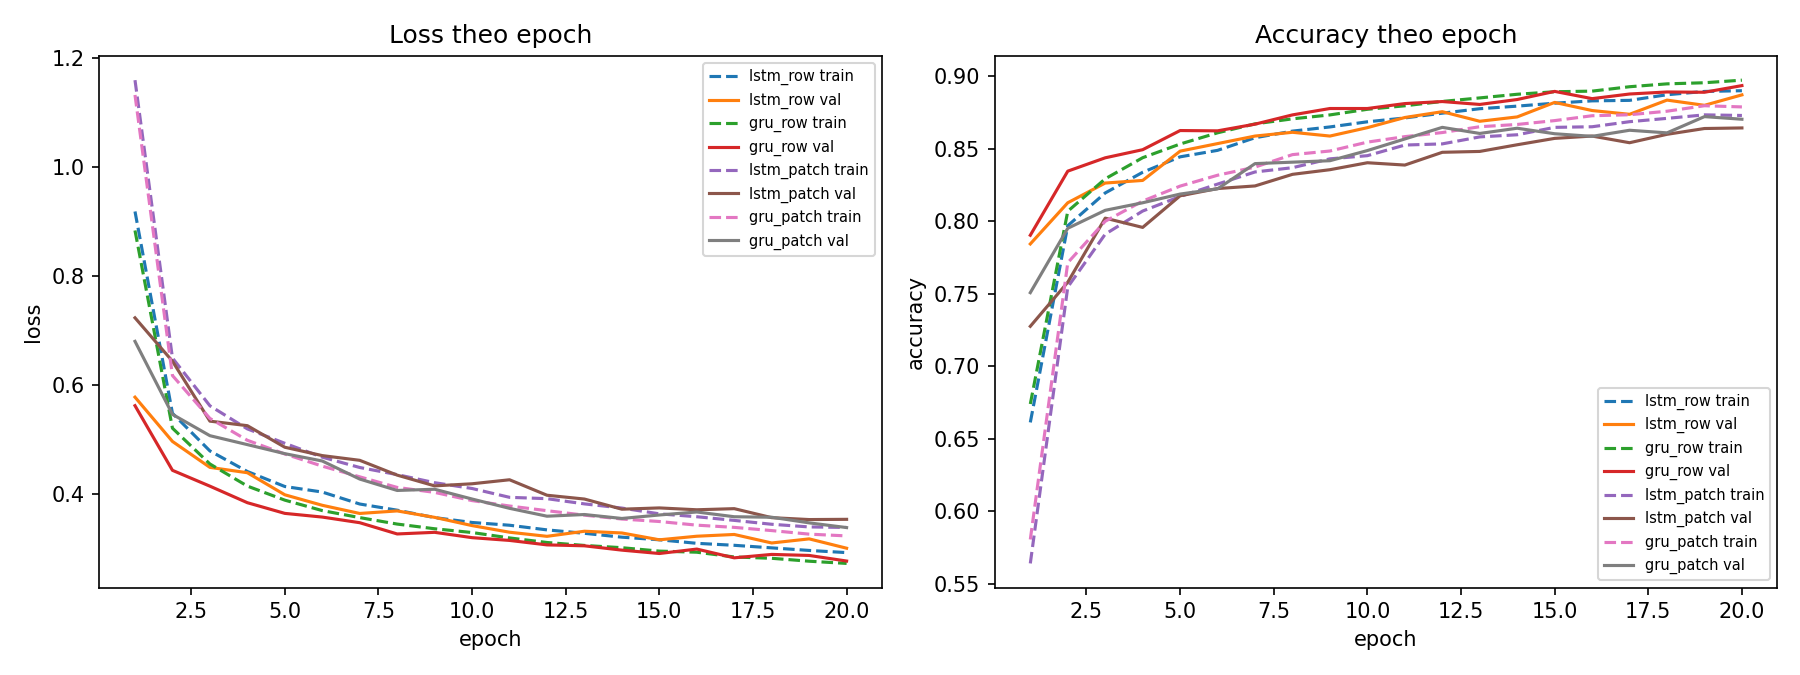

In [11]:
import pandas as pd
from IPython.display import Image, display

display(pd.read_csv("results/comparison_table.csv"))
display(Image("results/loss_accuracy_curves.png"))

## 7. Lưu kết quả

Thư mục results chứa checkpoint của từng run, log huấn luyện theo từng epoch,
bảng so sánh và biểu đồ, dùng để viết phần báo cáo của E3. Có thể chép thư
mục này vào Google Drive hoặc nén lại rồi tải thẳng về máy bằng hai cell bên
dưới.

In [13]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/CO5085_E3_results
!cp -r results /content/drive/MyDrive/CO5085_E3_results/

Mounted at /content/drive


In [14]:
import shutil
from google.colab import files

shutil.make_archive("/content/E3_results", "zip", "results")
files.download("/content/E3_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>